intro_to_Language_modeling part5 Cont..
-----

[video link](https://youtu.be/t3YJ5hKiMQ0)


<ins>Goal</ins>

Enhance the model from part3 to
1. Pytorch-ifye model further to add custom classes for Embedding,FlattenConsecutive & Sequential
2. Icrease context from 3 to 8 chars
3. Use Convolutional Neural Network (CNN) architecture, similar to WaveNet to capture local patterns/feature with a small,local window of the input chars

[Wavenet paper](https://arxiv.org/pdf/1609.03499)

Initial Setup
----

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

# # optional - debugging config
# %pip install ipdb --quiet
# import os
# os.environ['PYTHONBREAKPOINT'] = 'ipdb.set_trace'

In [3]:
# download the training data
!curl https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt -o names.txt -s

words = open('names.txt', 'r').read().splitlines()
words[0]

'emma'

In [4]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [5]:
# shuffle up the words
import random
random.seed(42)
random.shuffle(words)

In [6]:
# build the dataset for training,dev and test split
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
  X, Y = [], []

  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80% training split
Xdev, Ydev = build_dataset(words[n1:n2])   # 10% dev split
Xte,  Yte  = build_dataset(words[n2:])     # 10% test split

torch.Size([182580, 3]) torch.Size([182580])
torch.Size([22767, 3]) torch.Size([22767])
torch.Size([22799, 3]) torch.Size([22799])


In [7]:
for x,y in zip(Xtr[:20], Ytr[:20]): # show 20 inputs and outputs
  print(''.join(itos[ix.item()] for ix in x), '-->', itos[y.item()])

... --> e
..e --> b
.eb --> r
ebr --> i
bri --> m
rim --> a
ima --> .
... --> h
..h --> i
.hi --> l
hil --> t
ilt --> o
lto --> n
ton --> .
... --> j
..j --> h
.jh --> e
jhe --> n
hen --> e
ene --> .


In [8]:
# Custom classes for layers, BatchNorm1d etc(similar to classes in part3)
# The custom classes create here are the similar to api's of nn.Module in PyTorch

# to create a linear layer
class Linear: # similar to https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html

  def __init__(self, fan_in, fan_out, bias=True):
    # similar to Kaiming init that we did to fix saturated tanh
    self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5 # we could omit divison by 'fan_in**0.5', but keeping the Kaiming initialization (/ fan_in**0.5) is still a good practice and generally helps the training process.
    self.bias = torch.zeros(fan_out) if bias else None # biases initialized to zero

  def __call__(self, x): # similar to x@W+b
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out

  def parameters(self): # return parameters of this layer
    return [self.weight] + ([] if self.bias is None else [self.bias])


# for Batch Normalization
class BatchNorm1d: #similar to https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html

  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True # a flag to indicate if its for training phase
    # parameters (trained with backprop)
    self.gamma = torch.ones(dim) #similar to previous bngain
    self.beta = torch.zeros(dim) # similar to previous bnbias
    # buffers (trained with a running 'momentum update')
    self.running_mean = torch.zeros(dim) # similar to previous bnmean_running
    self.running_var = torch.ones(dim) # similar to previous bnstd_running

  def __call__(self, x):
    # calculate the forward pass
    if self.training:
      xmean = x.mean(0, keepdim=True) # batch mean
      xvar = x.var(0, keepdim=True) # batch variance
    else:
      xmean = self.running_mean
      xvar = self.running_var
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
    self.out = self.gamma * xhat + self.beta
    # update the buffers (similar how we updated bnmean_running and bnstd_running)
    if self.training:
      with torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out

  def parameters(self):
    return [self.gamma, self.beta]

# to claculate tanh
class Tanh:
  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out
  def parameters(self):
    return []


In [9]:
torch.manual_seed(42) # seed rng for reproducibility

A Baseline Code - Continue Pytorch-ifyied similar to Part3
----

In [10]:
# Init the model

n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

# init embedding
C = torch.randn((vocab_size, n_embd))

# init layer
layers = [
  Linear(n_embd * block_size, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(n_hidden, vocab_size),
]

# init parameters
with torch.no_grad():
  layers[-1].weight *= 0.1 # making last layer a bit less confident

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print("total parameters",sum(p.nelement() for p in parameters))
for p in parameters:
  p.requires_grad = True

total parameters 12097


In [51]:
# Training the network
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,))
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  emb = C[Xb] # embed the characters into vectors
  x = emb.view(emb.shape[0], -1) # concatenate the vectors. eg from [32, 3, 10] to [32, 30]
  ### dynamically creating layers
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad # stochastic gradient descent

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.3006
  10000/ 200000: 2.3788
  20000/ 200000: 2.4801
  30000/ 200000: 2.3083
  40000/ 200000: 2.0163
  50000/ 200000: 2.5618
  60000/ 200000: 2.5307
  70000/ 200000: 1.8858
  80000/ 200000: 1.8750
  90000/ 200000: 1.6711
 100000/ 200000: 2.2941
 110000/ 200000: 2.2802
 120000/ 200000: 2.2242
 130000/ 200000: 2.0855
 140000/ 200000: 2.4169
 150000/ 200000: 2.0249
 160000/ 200000: 1.9504
 170000/ 200000: 2.2795
 180000/ 200000: 2.1730
 190000/ 200000: 1.9756


torch.Size([32, 27])

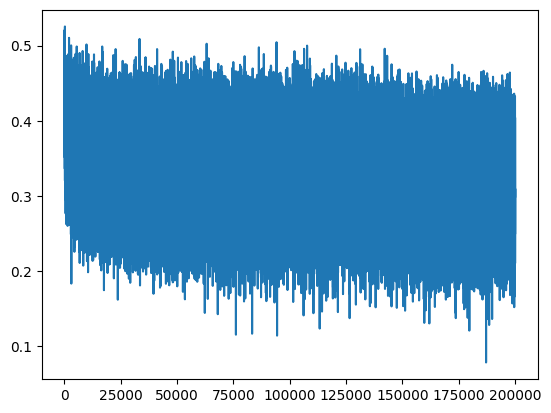

In [52]:
plt.plot(lossi)
x.shape

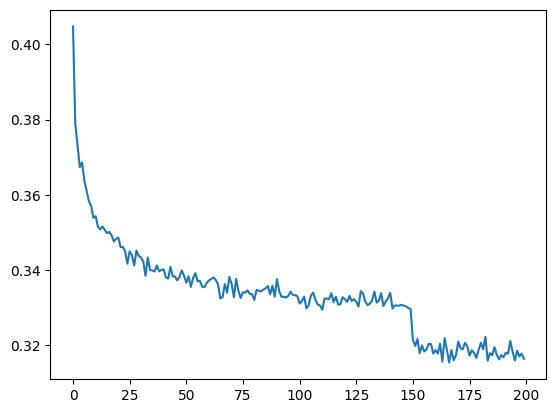

In [53]:
# plotting the loss in a more understandable way
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1)) # here we group all the losses into a [200, 1000] tensor and find the mean along the rows

In [54]:
# put layers into eval mode (needed for batchnorm especially)
for layer in layers:
  layer.training = False

In [55]:
# checking the train and val/dev loss
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  x = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0589990615844727
val 2.1079230308532715


Enhance the above model - futher Pytorch-ifying
----

In [14]:
# Custom classes for layers, BatchNorm1d etc(similar to classes in part3)
# The custom classes create here are the similar to api's of nn.Module in PyTorch

# to create a linear layer
class Linear: # similar to https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html

  def __init__(self, fan_in, fan_out, bias=True):
    # similar to Kaiming init that we did to fix saturated tanh
    self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5 # we could omit divison by 'fan_in**0.5', but keeping the Kaiming initialization (/ fan_in**0.5) is still a good practice and generally helps the training process.
    self.bias = torch.zeros(fan_out) if bias else None # biases initialized to zero

  def __call__(self, x): # similar to x@W+b
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out

  def parameters(self): # return parameters of this layer
    return [self.weight] + ([] if self.bias is None else [self.bias])


# for Batch Normalization
class BatchNorm1d: #similar to https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html

  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True # a flag to indicate if its for training phase
    # parameters (trained with backprop)
    self.gamma = torch.ones(dim) #similar to previous bngain
    self.beta = torch.zeros(dim) # similar to previous bnbias
    # buffers (trained with a running 'momentum update')
    self.running_mean = torch.zeros(dim) # similar to previous bnmean_running
    self.running_var = torch.ones(dim) # similar to previous bnstd_running

  def __call__(self, x):
    # calculate the forward pass
    if self.training:
      xmean = x.mean(0, keepdim=True) # batch mean
      xvar = x.var(0, keepdim=True) # batch variance
    else:
      xmean = self.running_mean
      xvar = self.running_var
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
    self.out = self.gamma * xhat + self.beta
    # update the buffers (similar how we updated bnmean_running and bnstd_running)
    if self.training:
      with torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out

  def parameters(self):
    return [self.gamma, self.beta]

# to claculate tanh
class Tanh:
  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out
  def parameters(self):
    return []
## Newly added classes ##

# class to do Embedding lookup
class Embedding:

  def __init__(self, num_embeddings, embedding_dim):
    self.weight = torch.randn((num_embeddings, embedding_dim)) # replacement of C = torch.randn((vocab_size, n_embd))

  def __call__(self, IX):
    self.out = self.weight[IX] # does the  looking up the embeddings for the given indices IX
    return self.out

  def parameters(self):
    return [self.weight]

# class to reshapes the (emedding)input tensor
class Flatten:

  def __call__(self, x):
    self.out = x.view(x.shape[0], -1) #flattens the input tensor x into a 2D tensor of shape (batch_size, -1)
    return self.out

  def parameters(self):
    return []

# class to run multiple layers sequentially
class Sequential:

  def __init__(self, layers):
    self.layers = layers

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    self.out = x
    return self.out

  def parameters(self):
    # get parameters of all layers and stretch them out into one list
    return [p for layer in self.layers for p in layer.parameters()]

In [57]:
# Init the model

n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP


# init layer
model = Sequential([
  Embedding(vocab_size, n_embd),
  Flatten(),
  Linear(n_embd * block_size, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(n_hidden, vocab_size),
])

# init parameters
with torch.no_grad():
  layers[-1].weight *= 0.1 # making last layer a bit less confident

parameters = model.parameters()
print("total parameters",sum(p.nelement() for p in parameters))
for p in parameters:
  p.requires_grad = True

total parameters 12097


In [58]:
# Training the network
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,))
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  x = Xb
  ### dynamically calling model
  logits = model(x)
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad # stochastic gradient descent

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())


      0/ 200000: 3.6249
  10000/ 200000: 1.7753
  20000/ 200000: 2.5839
  30000/ 200000: 2.1584
  40000/ 200000: 2.2715
  50000/ 200000: 1.9542
  60000/ 200000: 1.9831
  70000/ 200000: 1.9874
  80000/ 200000: 2.1301
  90000/ 200000: 2.1157
 100000/ 200000: 2.3883
 110000/ 200000: 2.2440
 120000/ 200000: 2.0886
 130000/ 200000: 2.1799
 140000/ 200000: 2.2397
 150000/ 200000: 1.9442
 160000/ 200000: 1.8737
 170000/ 200000: 1.5184
 180000/ 200000: 1.8914
 190000/ 200000: 1.9628


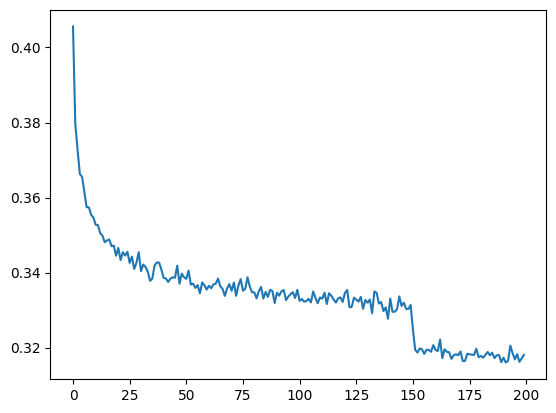

In [59]:
# plotting the loss in a more understandable way
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1)) # here we group all the losses into a [200, 1000] tensor and find the mean along the rows

In [60]:
# put layers into eval mode (needed for batchnorm especially)
for layer in model.layers:
  layer.training = False

In [61]:
# evaluate the loss
@torch.no_grad() # this decorator disables gradient tracking inside pytorch
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  logits = model(x)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.059783935546875
val 2.1059727668762207


In [62]:
# # Sample to show input and output shapes in each layer
# ix = torch.randint(0, Xtr.shape[0], (4,))
# sample_input = Xtr[ix]

# # print(f"Input shape to the model: {sample_input.shape}\n")
# x = sample_input
# for i, layer in enumerate(model.layers):
#     print(f"Layer {i+1}: {layer.__class__.__name__}")
#     if i == 0:
#         print(f"  Input shape: {x.shape}")
#     else:
#         print(f"  Input shape: {input_shape}") # Use the output shape from the previous layer

#     x = layer(x)
#     input_shape = x.shape # Store the output shape for the next iteration
#     print(f"  Output shape: {x.shape}\n")

Input shape to the model: torch.Size([4, 3])

Layer 1: Embedding
  Input shape: torch.Size([4, 3])
  Output shape: torch.Size([4, 3, 10])

Layer 2: Flatten
  Input shape: torch.Size([4, 3, 10])
  Output shape: torch.Size([4, 30])

Layer 3: Linear
  Input shape: torch.Size([4, 30])
  Output shape: torch.Size([4, 200])

Layer 4: BatchNorm1d
  Input shape: torch.Size([4, 200])
  Output shape: torch.Size([4, 200])

Layer 5: Tanh
  Input shape: torch.Size([4, 200])
  Output shape: torch.Size([4, 200])

Layer 6: Linear
  Input shape: torch.Size([4, 200])
  Output shape: torch.Size([4, 27])



Enhance further to increase the context and use architecture similar to WaveNet to capture local patterns/feature
----

This allows model to identify recurring, meaningful patterns within small segments of the input text

In [11]:
# context length changed from 3 to 8 chars
# this build the dataset for training,dev and test split
block_size = 8 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
  X, Y = [], []

  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80% training split
Xdev, Ydev = build_dataset(words[n1:n2])   # 10% dev split
Xte,  Yte  = build_dataset(words[n2:])     # 10% test split

torch.Size([182437, 8]) torch.Size([182437])
torch.Size([22781, 8]) torch.Size([22781])
torch.Size([22928, 8]) torch.Size([22928])


In [12]:
for x,y in zip(Xtr[:20], Ytr[:20]): # show 20 inputs and outputs
  print(''.join(itos[ix.item()] for ix in x), '-->', itos[y.item()])

........ --> t
.......t --> a
......ta --> u
.....tau --> r
....taur --> e
...taure --> n
..tauren --> .
........ --> s
.......s --> u
......su --> l
.....sul --> e
....sule --> m
...sulem --> a
..sulema --> n
.suleman --> .
........ --> z
.......z --> e
......ze --> r
.....zer --> e
....zere --> n


In [15]:
# Init the model

n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP


# init layer
model = Sequential([
  Embedding(vocab_size, n_embd),
  Flatten(),
  Linear(n_embd * block_size, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(n_hidden, vocab_size),
])

# init parameters
with torch.no_grad():
  layers[-1].weight *= 0.1 # making last layer a bit less confident

parameters = model.parameters()
print("total parameters",sum(p.nelement() for p in parameters))
for p in parameters:
  p.requires_grad = True

total parameters 22097


In [16]:
# Training the network
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,))
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  # forward pass
  x = Xb
  ### dynamically calling model
  logits = model(x)
  loss = F.cross_entropy(logits, Yb) # loss function

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad # SDG-stochastic gradient descent

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())
  break

      0/ 200000: 3.5656


In [ ]:
# plotting the loss in a more understandable way
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1)) # here we group all the losses into a [200, 1000] tensor and find the mean along the rows